# Phases 3 and 4 - Preprocessing, RUL Labels and Feature Representations

## Part A - Preprocessing and RUL label construction (Phase 3)

**Objective.** Turn the raw FD001 and FD002 files into model-ready tables: build the RUL target, remove sensors that carry no information, and normalise the rest.

**Why this is needed.** The models in Phases 5 and 6 need a target to predict and inputs on a comparable scale. RQ2 asks how preprocessing affects performance, so two normalisation schemes are prepared side by side.

**Leakage rule.** Which sensors to drop, and every mean and standard deviation used for scaling, are computed from training engines only. Test engines are transformed with those training values.

All logic lives in `src/preprocessing.py`.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl
from src import preprocessing as pp

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 4)

# Write processed data, tables, the config record and figures in one step
saved = pp.run_all()
for name, path in saved.items():
    print(f'{name:38s} -> {path.relative_to(dl.PROJECT_ROOT)}')

FD001_global_train                     -> data\processed\FD001_global_train.csv
FD001_global_test                      -> data\processed\FD001_global_test.csv
FD002_global_train                     -> data\processed\FD002_global_train.csv
FD002_global_test                      -> data\processed\FD002_global_test.csv
FD002_condition_train                  -> data\processed\FD002_condition_train.csv
FD002_condition_test                   -> data\processed\FD002_condition_test.csv
phase3_preprocessing_summary           -> results\tables\phase3_preprocessing_summary.csv
phase3_scaler_parameters               -> results\tables\phase3_scaler_parameters.csv
phase3_preprocessing_config            -> results\metrics\phase3_preprocessing_config.json
fig03a_rul_target                      -> results\figures\fig03a_rul_target.png
fig03b_normalisation_effect_FD002      -> results\figures\fig03b_normalisation_effect_FD002.png


## 1. RUL labels

- **Training engines** run until failure, so the RUL on any row is the number of cycles left until that engine's last row (0 on the last row).
- **Test engines** stop early. NASA publishes the true RUL at each engine's last recorded cycle; earlier rows are that value plus the cycles still to come.
- **Cap at 125.** Phase 2 showed sensors are flat in early life, so they cannot tell a model whether 300 or 200 cycles remain. The target is therefore held at 125 until the engine has 125 cycles left and then counts down linearly. `rul_uncapped` keeps the original value for reference.

In [2]:
train = pp.add_train_rul(dl.load_train('FD001'))
engine = train[train['unit'] == 1][['unit', 'cycle', 'rul_uncapped', 'rul']]
print('Engine 1 of FD001 has', len(engine), 'cycles')
pd.concat([engine.head(3), engine.iloc[65:69], engine.tail(3)])

Engine 1 of FD001 has 192 cycles


,unit,cycle,rul_uncapped,rul
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
65,1,66,126,125
66,1,67,125,125
67,1,68,124,124
68,1,69,123,123
189,1,190,2,2
190,1,191,1,1
191,1,192,0,0


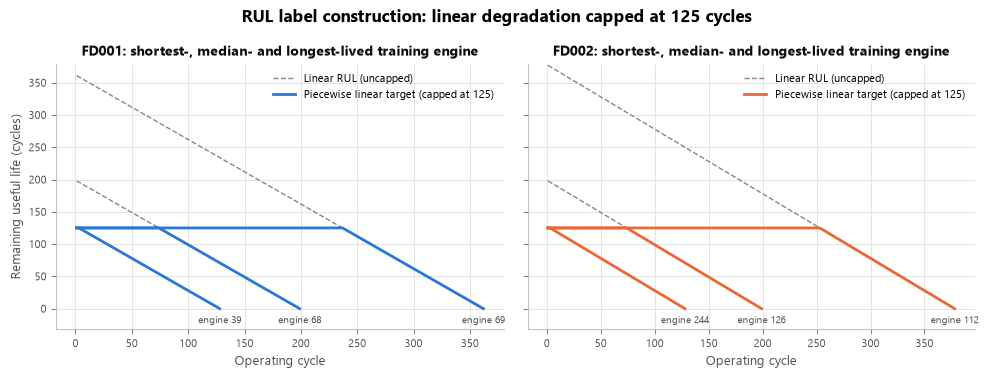

In [3]:
fig = pp.plot_rul_target()
plt.show()

**Reading the figure.** The dashed line is the plain countdown to failure. The solid line is the target the models will learn: flat at 125 while the engine is healthy, then the same countdown.

## 2. Removing uninformative sensors

Rule: drop a sensor if it has a single unique value in the training data inside every normalisation group. For dataset-wide normalisation the group is the whole file. For per-condition normalisation there is one group per operating condition, so a sensor that never changes inside any condition is dropped (after scaling it would be zero everywhere).

In [4]:
rows = []
for subset in dl.SUBSETS:
    raw_train = dl.load_train(subset)
    for scheme in pp.SCHEMES:
        dropped = pp.find_constant_sensors(raw_train, scheme)
        rows.append({'subset': subset, 'scheme': scheme,
                     'dropped': ', '.join(dropped) or 'none', 'retained': 21 - len(dropped)})
pd.DataFrame(rows)

,subset,scheme,dropped,retained
0,FD001,global,"s1, s5, s10, s16, s18, s19",15
1,FD001,condition,"s1, s5, s10, s16, s18, s19",15
2,FD002,global,none,21
3,FD002,condition,"s1, s5, s18, s19",17


**Reading the table.** FD001 loses the same six sensors under both schemes because it has one operating condition. FD002 keeps all 21 sensors under dataset-wide normalisation, and loses s1, s5, s18 and s19 under per-condition normalisation. Those four only repeat which condition the engine is in.

## 3. Normalisation

Both schemes use the z-score, `(value - mean) / standard deviation`.

- **global:** one mean and standard deviation per sensor for the whole training file.
- **condition:** one mean and standard deviation per sensor for each operating condition.

Using the same formula in both means the only difference between them is the grouping.

In [5]:
results = {grid: pp.preprocess(*grid) for grid in pp.EXPERIMENT_GRID}
pd.DataFrame([pp.label_summary(r) for r in results.values()]).T

,0,1,2
subset,FD001,FD002,FD002
scheme,global,global,condition
sensors_retained,15,21,17
sensors_dropped,"s1, s5, s10, s16, s18, s19",none,"s1, s5, s18, s19"
train_rows,20631,53759,53759
train_rows_at_cap_percent,39.4,39.5,39.5
test_rows,13096,33991,33991
test_engines,100,259,259
test_engines_true_rul_above_cap,11,57,57


In [6]:
results[('FD002', 'condition')]['train'].head()

,unit,cycle,condition,s2,s3,s4,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s20,s21,rul_uncapped,rul
0,1,1,35 / 0.84 / 100,-1.0903,-1.4431,0.7700,-0.1747,0.4127,-1.4008,-0.8355,-0.2016,0.1636,0.0977,-1.3958,-1.5316,0.3617,0.0,-0.1674,-0.8904,-1.3523,148,125
1,1,2,42 / 0.84 / 100,0.4508,-0.2207,-0.2648,-1.1848,-0.2742,-1.3398,-1.3284,-0.1583,0.2145,-0.3802,-1.2133,-1.0401,0.0625,0.0,-0.7571,-1.6348,-1.3156,147,125
2,1,3,25 / 0.62 / 60,1.2425,-1.1221,-0.4217,-1.8562,0.6344,-1.1659,-0.9985,0.0891,-0.5342,-1.0245,-1.0245,-1.0423,-0.4597,0.0,1.2778,-1.6314,1.7205,146,125
3,1,4,42 / 0.84 / 100,-0.4502,-0.0769,-0.1863,-1.1848,-0.3880,-1.3064,-1.3284,-0.1583,-0.7906,0.5005,-1.3680,-1.2610,-0.5932,0.0,-1.4670,0.0332,1.8454,145,125
4,1,5,25 / 0.62 / 60,0.5723,-0.9422,-0.3512,0.5356,-0.8397,-1.2040,-1.5794,0.0891,0.4251,-0.7627,-1.1327,-1.3215,-0.4088,0.0,1.2778,-1.1853,-0.4512,144,125


In [7]:
# Check: FD001 gives the same numbers under both schemes (one operating condition)
a, b = pp.preprocess('FD001', 'global'), pp.preprocess('FD001', 'condition')
diff = (a['train'][a['sensors']] - b['train'][b['sensors']]).abs().max().max()
print('Largest difference between the two schemes on FD001:', diff)

Largest difference between the two schemes on FD001: 0.0


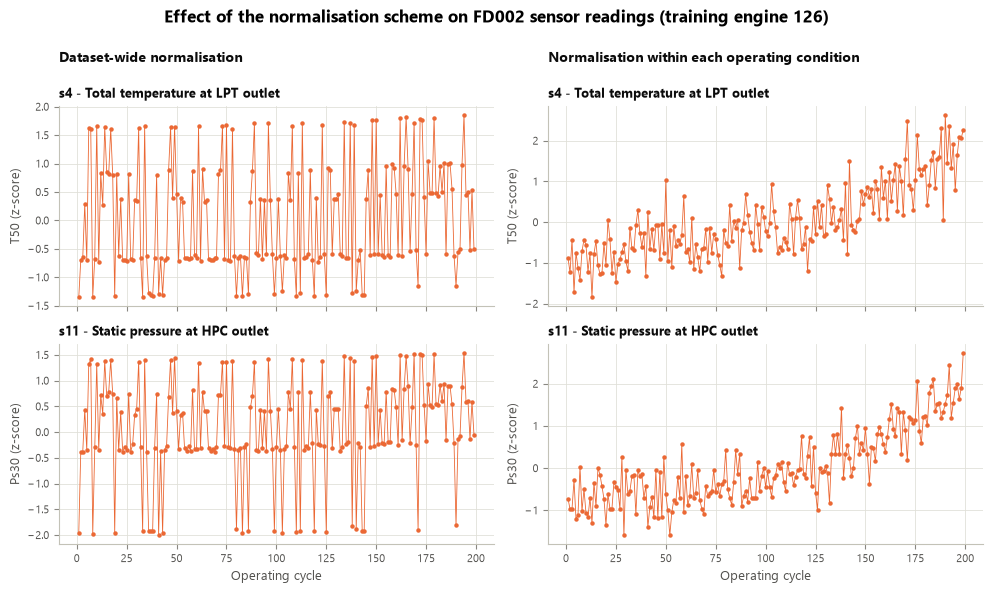

In [8]:
fig = pp.plot_normalisation_effect()
plt.show()

**Reading the figure.** Left: with dataset-wide normalisation the readings still jump between regime levels, exactly as in the raw data. Only the units on the axis changed. Right: normalising inside each operating condition removes the jumps and the wear trend becomes visible.

## 4. Does the degradation signal survive? (training data)

In [9]:
rows = []
for (subset, scheme), r in results.items():
    rho = r['train'][r['sensors']].corrwith(r['train']['rul'], method='spearman').abs()
    rows.append({'subset': subset, 'scheme': scheme, 'sensors': len(r['sensors']),
                 'strongest sensor': rho.idxmax(), 'max |Spearman| with RUL': rho.max(),
                 'median |Spearman| with RUL': rho.median()})
pd.DataFrame(rows)

,subset,scheme,sensors,strongest sensor,max |Spearman| with RUL,median |Spearman| with RUL
0,FD001,global,15,s11,0.7199,0.6353
1,FD002,global,21,s13,0.2504,0.0778
2,FD002,condition,17,s11,0.7150,0.4544


**Reading the table.** These are rank correlations between each scaled sensor and the capped RUL on the training engines. On FD002 the per-condition scheme lifts the correlations to roughly the FD001 level. This describes the inputs only. Whether it improves *model* accuracy is tested in Phase 5.

## 5. A side effect to know about: quantised sensors

In [10]:
r = results[('FD002', 'condition')]
x = r['train'][r['sensors']]
extreme = pd.DataFrame({'min z': x.min(), 'max z': x.max()})
display(extreme[(extreme['min z'] < -8) | (extreme['max z'] > 8)].round(2))
raw = dl.load_train('FD002')
raw.groupby(pp.condition_key(raw))[['s6', 's10', 's16']].nunique()

,min z,max z
s9,-2.20,8.35
s10,-51.94,6.32
s14,-2.50,8.08


,s6,s10,s16
0 / 0.00 / 100,2,1,1
10 / 0.25 / 100,2,2,1
20 / 0.70 / 100,3,2,2
25 / 0.62 / 60,3,2,1
35 / 0.84 / 100,2,2,1
42 / 0.84 / 100,2,2,1


**Reading the tables.** Sensors s6, s10 and s16 are recorded with very few distinct values. Inside one operating condition s10 is almost always 1.26 with a handful of readings at 1.25, so its standard deviation is tiny and those rare readings become very large z-scores (about -52). The arithmetic is correct. Tree models split on thresholds and are not affected by the size of a value, but this is recorded as a limitation and matters for the Isolation Forest in Phase 6, which reacts to rare values.

## 6. Outputs

| File | Content |
|---|---|
| `data/processed/FD001_global_{train,test}.csv` | FD001, 15 sensors |
| `data/processed/FD002_global_{train,test}.csv` | FD002, dataset-wide normalisation, 21 sensors |
| `data/processed/FD002_condition_{train,test}.csv` | FD002, per-condition normalisation, 17 sensors |
| `results/tables/phase3_preprocessing_summary.csv` | Row counts, sensors kept, share of rows at the cap |
| `results/tables/phase3_scaler_parameters.csv` | Every fitted mean and standard deviation |
| `results/metrics/phase3_preprocessing_config.json` | The rules and settings used |

Each processed table has `unit`, `cycle`, `condition`, the scaled sensors, `rul_uncapped` and `rul`.

# Part B - Feature Representations (Phase 4)

**Objective.** Build the two sets of model inputs that RQ2 compares.

**Why this is needed.** Experiment 3 asks whether describing each cycle by simple statistics of recent readings predicts RUL better than the single reading of that cycle.

| Representation | One row is | Inputs per sensor |
|---|---|---|
| A - raw | one engine cycle | the scaled reading of that cycle |
| B - summary | one engine cycle | last value, mean and standard deviation over the most recent 30 cycles |

Both have the same rows and the same targets, so any difference in model accuracy comes from the inputs alone. Representation B contains A (the last value is the raw reading) plus two extra columns per sensor.

**Rules.** Windows look backwards only, never cross from one engine to another, and use the cycles available so far when an engine has fewer than 30. Nothing is fitted in this step.

All logic lives in `src/feature_engineering.py`.

In [11]:
from src import feature_engineering as fe

saved = fe.run_all()
for name, path in saved.items():
    print(f'{name:34s} -> {path.relative_to(dl.PROJECT_ROOT)}')

phase4_feature_sets                -> results\tables\phase4_feature_sets.csv
phase4_feature_signal              -> results\tables\phase4_feature_signal.csv
phase4_feature_names               -> results\tables\phase4_feature_names.csv
fig03c_summary_features_example    -> results\figures\fig03c_summary_features_example.png


## 7. Size of each feature set

In [12]:
fe.feature_set_summary()

,subset,scheme,representation,sensors,features,train_rows,test_rows,test_engines,test_engines_shorter_than_window
0,FD001,global,raw,15,15,20631,13096,100,0
1,FD001,global,summary,15,45,20631,13096,100,0
2,FD002,global,raw,21,21,53759,33991,259,0
3,FD002,global,summary,21,63,53759,33991,259,6
4,FD002,condition,raw,17,17,53759,33991,259,0
5,FD002,condition,summary,17,51,53759,33991,259,6


**Reading the table.** Representation B has three times as many inputs as A and exactly the same number of rows. Six FD002 test engines are shorter than 30 cycles; their features use the cycles available.

## 8. What the summary features look like

In [13]:
built = fe.build('FD001', 'global', 'summary')
engine = built['train'][built['train']['unit'] == 1]
engine.loc[engine['cycle'].isin([1, 2, 3, 30, 31]),
           ['unit', 'cycle', 's11_last', 's11_mean', 's11_std', 'rul']]

,unit,cycle,s11_last,s11_mean,s11_std,rul
0,1,1,-0.2665,-0.2665,0.0000,125
1,1,2,-0.1916,-0.2290,0.0374,125
2,1,3,-1.0153,-0.4911,0.3719,125
29,1,30,-0.5286,-0.9679,0.4288,125
30,1,31,-0.4911,-0.9754,0.4183,125


At cycle 1 only one reading exists, so the mean equals the reading and the standard deviation is 0. From cycle 30 onwards the window is full and slides forward one cycle at a time.

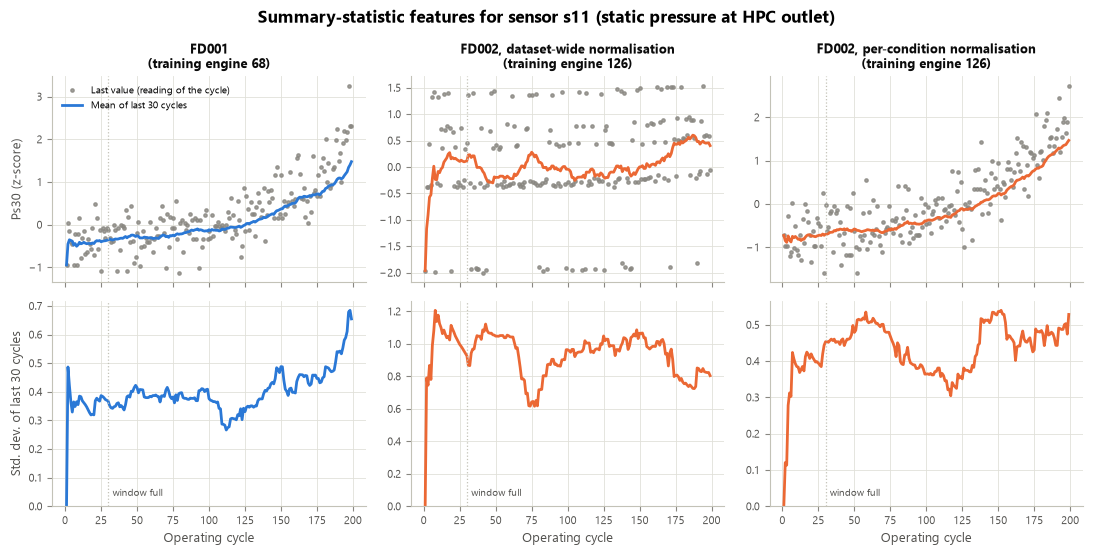

In [14]:
fig = fe.plot_summary_features()
plt.show()

**Reading the figure.** Top row: grey dots are the readings of each cycle and the line is the 30-cycle mean. In FD001 and in FD002 with per-condition normalisation the mean follows the wear trend with far less noise than single readings. In FD002 with dataset-wide normalisation the readings still sit on separate regime levels, and the mean mostly reflects which regimes happened to fall inside the window. Bottom row: the 30-cycle standard deviation.

## 9. Do the summary features track RUL? (training data)

In [15]:
fe.feature_signal_summary()

,subset,scheme,statistic,features,median_abs_spearman,max_abs_spearman,strongest_feature
0,FD001,global,last,15,0.6353,0.7199,s11_last
1,FD001,global,mean,15,0.7074,0.7286,s17_mean
2,FD001,global,std,15,0.3198,0.4860,s14_std
3,FD002,global,last,21,0.0778,0.2504,s13_last
4,FD002,global,mean,21,0.0477,0.2521,s16_mean
5,FD002,global,std,21,0.0717,0.2721,s16_std
6,FD002,condition,last,17,0.4544,0.7150,s11_last
7,FD002,condition,mean,17,0.6875,0.7412,s17_mean
8,FD002,condition,std,17,0.2577,0.4690,s16_std


**Reading the table.** For each kind of feature this is the absolute rank correlation with the capped RUL on the training engines. The window mean is more strongly related to RUL than the single reading in FD001 and in FD002 with per-condition normalisation. In FD002 with dataset-wide normalisation no statistic helps. These are descriptions of the inputs. Model accuracy is measured in Phase 5.